In [41]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np

from scipy.special import lambertw
from scipy.stats import norm

def final_size_mn(R0, s0=1.0):
    """
    Compute epidemic final size

    R0: basic reproductive number
    s0: initial fraction susceptible (optional, default = 1)
    """
    if (s0>1) or (s0<0):
        raise ValueError("s0 must be between 0 and 1")

    Reff = s0*R0

    if Reff <= 1:
        return 0

    s_final = -(1/R0) * lambertw(-Reff * np.exp(-Reff) ).real

    return s0 - s_final

def final_size_sd(R0, N, r=1):
    # eq (1) of https://www.stat.berkeley.edu/~aldous/260-FMIE/Papers/britton.pdf
    # "r^2 = V (I)/(E(I))^2 is the squared coefficient of variation of the infectious period"
    # Exponential distribution

    z = final_size_mn(R0)

    return np.sqrt(N * z * (1-z) * (1 + r**2 *(1-z) * R0)) / (1 - R0 * (1-z))

R0 = 1.2
R0_str = f"{R0:.3f}".rstrip('0').rstrip('.').replace('.', 'p')

In [42]:
def load_sims(method):
    files = sorted(Path(".").glob(f"results_{R0_str}_{method}_*.csv"))

    dat = pd.concat(
        [pd.read_csv(f) for f in files],
        ignore_index=True
    )

    return dat

param_sets = {
    'cao2006': [0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
    'fixed_tau': [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 10.0],
    'ukhsa2026': [0.02, 0.05, 0.1, 0.2, 0.5],
    'direct': [0]
}

dats = []
for method in param_sets.keys():
    dats.append(load_sims(method))

dats = pd.concat(dats)

# Target values

In [43]:
beta = dats['beta'].iloc[0]
gamma = dats['gamma'].iloc[0]
N = dats['N'].iloc[0]

targets_analytic = {
    "mn": N * final_size_mn(R0),
    "sd": final_size_sd(R0, N),
    "p_fail": 1 / R0
}

def get_metrics(df, threshold):
    fail = df[df['final_size'] < threshold]
    succ = df[df['final_size'] >= threshold]

    p_fail = len(fail) / len(df)
    mn = succ['final_size'].mean()
    sd = succ['final_size'].std()

    time = succ['cpu_time_seconds'].mean()

    return {
        'mn': mn,
        'sd': sd,
        'p_fail': p_fail,
        'time': time
        # 'n_steps'
    }

direct = dats[dats['method'] == 'direct']
threshold = 10000

metrics = get_metrics(direct, threshold)

targets_exact = {
    "mn": metrics['mn'],
    "sd": metrics['sd'],
    "p_fail": metrics['p_fail']
}

targets = {
    'analytic': targets_analytic,
    'exact': targets_exact
}

In [46]:
out = []

for method in param_sets.keys():
    dat = dats[dats['method'] == method]
    params = param_sets[method]
    for param in params:
        df = dat[dat['param'] == param]

        metrics = get_metrics(df, threshold)

        row = {
            'method': method,
            'param': param,
            'mn': metrics['mn'],
            'sd': metrics['sd'],
            'p_fail': metrics['p_fail'],
            'time': metrics['time']
        }

        out.append(row)

out = pd.DataFrame(out)

for target_type, target_vals in targets.items():
    for target_name, target_value in target_vals.items():
        out[f'{target_name}_{target_type}_err'] = abs(out[target_name] - target_value) / target_value

def plot_performance(out, target_type):

    target = targets[target_type]

    fig, axes = plt.subplots(1, len(target), figsize=(12,4))

    for method in param_sets.keys():
        df = out[out['method'] == method]

        for i, target_name in enumerate(target.keys()):
            if method != "direct":
                axes[i].plot(df['time'], df[f'{target_name}_{target_type}_err'], label=method, marker = 'o')
            
            axes[i].set_title(target_name)


    import matplotlib.ticker as mticker

    for ax in axes:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Relative Error")
        ax.set_ylim(1e-5, 1e0)
        # ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3g'))
        # ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3g'))

    axes[0].legend()
    plt.suptitle(f"Target type: {target_type}")
    plt.tight_layout()
    plt.show()

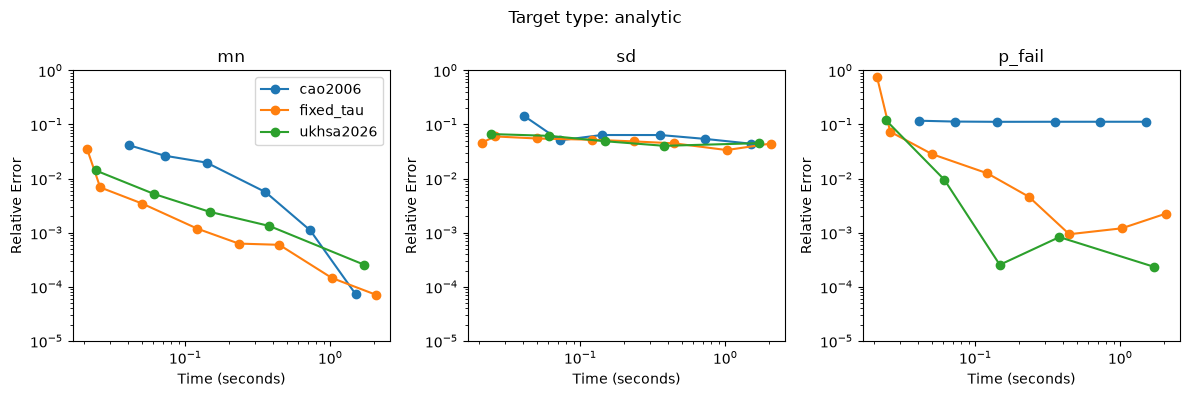

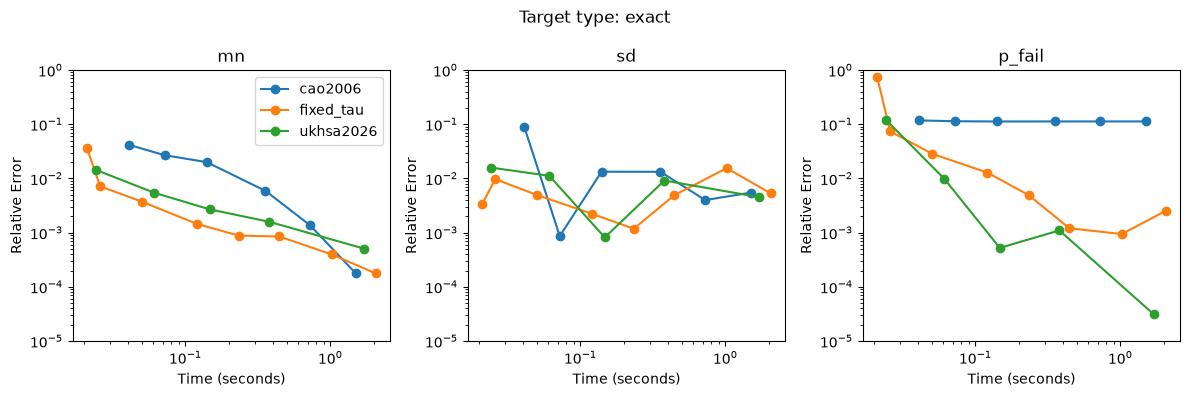

In [47]:
plot_performance(out, 'analytic')
plot_performance(out, 'exact')